In [27]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/Not_MRI/motorbike/motorbike_0786.jpg
/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/Not_MRI/motorbike/motorbike_0344.jpg
/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/Not_MRI/motorbike/motorbike_0360.jpg
/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/Not_MRI/motorbike/motorbike_0010.jpg
/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/Not_MRI/motorbike/motorbike_0125.jpg
/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/Not_MRI/motorbike/motorbike_0211.jpg
/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/Not_MRI/motorbike/motorbike_0135.jpg
/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/Not_MRI/motorbike/motorbike_0769.jpg
/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/Not_MRI/motorbike/motorbike_0146.jpg
/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/Not_MRI/motorbike/motorbike_0456.jpg
/kaggle/in

**Stage1**

In [34]:
import os
import glob
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.utils import class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    confusion_matrix, roc_auc_score
)


In [35]:
MRI_DIRS = [
    "/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/MRI"
]

NOT_MRI_DIRS = [
    "/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/Not_MRI"
]

def collect_binary_images(mri_dirs, not_mri_dirs):
    exts = ["*.png", "*.jpg", "*.jpeg", "*.PNG", "*.JPG", "*.JPEG"]
    rec = []

    for d in mri_dirs:
        for ext in exts:
            for p in glob.glob(os.path.join(d, "**", ext), recursive=True):
                rec.append((p, 1))  # MRI = 1

    for d in not_mri_dirs:
        for ext in exts:
            for p in glob.glob(os.path.join(d, "**", ext), recursive=True):
                rec.append((p, 0))  # Not MRI = 0

    df = pd.DataFrame(rec, columns=["filepath", "label"])
    return df

df_binary = collect_binary_images(MRI_DIRS, NOT_MRI_DIRS)

print("Total images:", len(df_binary))
print(df_binary["label"].value_counts())

Total images: 54720
label
1    39100
0    15620
Name: count, dtype: int64


In [36]:
train_df, test_df = train_test_split(
    df_binary,
    test_size=0.2,
    stratify=df_binary["label"],
    random_state=42
)

In [37]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def df_to_binary_dataset(df, shuffle=False):
    paths = df["filepath"].values
    labels = df["label"].values.astype(np.float32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        ds = ds.shuffle(len(df))

    def _map(path, label):
        img = tf.io.read_file(path)
        img = tf.image.decode_image(img, channels=3, expand_animations=False)
        img.set_shape([None, None, 3])
        img = tf.image.resize(img, IMG_SIZE)
        img = tf.cast(img, tf.float32) / 255.0  # نفس normalization
        return img, label

    ds = ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds

train_ds_bin = df_to_binary_dataset(train_df, shuffle=True)
test_ds_bin  = df_to_binary_dataset(test_df)

In [38]:
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_df['label']),
    y=train_df['label']
)

class_weights_dict = {
    int(c): w for c, w in zip(np.unique(train_df['label']), class_weights)
}

print("Class weights:", class_weights_dict)


Class weights: {0: np.float64(1.7516005121638925), 1: np.float64(0.6997442455242967)}


In [39]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)

# Fine-tune آخر 30 layer
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers[-30:]:
    layer.trainable = True

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.4)(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.3)(x)
output = Dense(1, activation="sigmoid")(x)

model = Model(inputs=base_model.input, outputs=output)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

model.summary()


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer_3[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,112,513 (91.98 MB)

 Trainable params: 14,974,977 (57.13 MB)

 Non-trainable params: 9,137,536 (34.86 MB)

In [40]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_binary_model.h5",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

callbacks_list = [early_stop, reduce_lr, checkpoint]


In [41]:
EPOCHS = 20

history = model.fit(
    train_ds_bin,
    validation_data=test_ds_bin,
    epochs=EPOCHS,
    class_weight=class_weights_dict,
    callbacks=callbacks_list
)


Epoch 1/20
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9589 - auc: 0.9906 - loss: 0.1023
Epoch 1: val_loss improved from inf to 0.10900, saving model to best_binary_model.h5


1368/1368 ━━━━━━━━━━━━━━━━━━━━ 136s 85ms/step - accuracy: 0.9589 - auc: 0.9906 - loss: 0.1022 - val_accuracy: 0.9609 - val_auc: 0.9977 - val_loss: 0.1090 - learning_rate: 1.0000e-04
Epoch 2/20
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9883 - auc: 0.9989 - loss: 0.0331
Epoch 2: val_loss did not improve from 0.10900
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 111s 81ms/step - accuracy: 0.9883 - auc: 0.9989 - loss: 0.0331 - val_accuracy: 0.8480 - val_auc: 0.8561 - val_loss: 1.0084 - learning_rate: 1.0000e-04
Epoch 3/20
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9908 - auc: 0.9993 - loss: 0.0252
Epoch 3: val_loss improved from 0.10900 to 0.02862, saving model to best_binary_model.h5


1368/1368 ━━━━━━━━━━━━━━━━━━━━ 112s 82ms/step - accuracy: 0.9908 - auc: 0.9993 - loss: 0.0252 - val_accuracy: 0.9906 - val_auc: 0.9988 - val_loss: 0.0286 - learning_rate: 1.0000e-04
Epoch 4/20
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9928 - auc: 0.9993 - loss: 0.0209
Epoch 4: val_loss did not improve from 0.02862
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 112s 82ms/step - accuracy: 0.9928 - auc: 0.9993 - loss: 0.0209 - val_accuracy: 0.8723 - val_auc: 0.9364 - val_loss: 0.5446 - learning_rate: 1.0000e-04
Epoch 5/20
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9940 - auc: 0.9996 - loss: 0.0171
Epoch 5: val_loss improved from 0.02862 to 0.02395, saving model to best_binary_model.h5


1368/1368 ━━━━━━━━━━━━━━━━━━━━ 112s 82ms/step - accuracy: 0.9940 - auc: 0.9996 - loss: 0.0171 - val_accuracy: 0.9924 - val_auc: 0.9996 - val_loss: 0.0239 - learning_rate: 1.0000e-04
Epoch 6/20
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9945 - auc: 0.9995 - loss: 0.0170
Epoch 6: val_loss did not improve from 0.02395
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 111s 81ms/step - accuracy: 0.9945 - auc: 0.9995 - loss: 0.0170 - val_accuracy: 0.9580 - val_auc: 0.9898 - val_loss: 0.1346 - learning_rate: 1.0000e-04
Epoch 7/20
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9949 - auc: 0.9996 - loss: 0.0146
Epoch 7: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.

Epoch 7: val_loss did not improve from 0.02395
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 111s 81ms/step - accuracy: 0.9949 - auc: 0.9996 - loss: 0.0146 - val_accuracy: 0.9200 - val_auc: 0.9762 - val_loss: 0.2768 - learning_rate: 1.0000e-04
Epoch 8/20
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.9971 - a

1368/1368 ━━━━━━━━━━━━━━━━━━━━ 112s 82ms/step - accuracy: 0.9971 - auc: 0.9998 - loss: 0.0088 - val_accuracy: 0.9975 - val_auc: 0.9999 - val_loss: 0.0073 - learning_rate: 5.0000e-05
Epoch 9/20
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.9974 - auc: 0.9999 - loss: 0.0074
Epoch 9: val_loss did not improve from 0.00726
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 112s 82ms/step - accuracy: 0.9974 - auc: 0.9999 - loss: 0.0074 - val_accuracy: 0.9941 - val_auc: 0.9991 - val_loss: 0.0174 - learning_rate: 5.0000e-05
Epoch 10/20
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.9977 - auc: 0.9999 - loss: 0.0056
Epoch 10: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.

Epoch 10: val_loss did not improve from 0.00726
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 113s 82ms/step - accuracy: 0.9977 - auc: 0.9999 - loss: 0.0056 - val_accuracy: 0.9962 - val_auc: 0.9999 - val_loss: 0.0109 - learning_rate: 5.0000e-05
Epoch 11/20
1368/1368 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.9991


Test Accuracy      : 99.753%
Precision (macro)  : 99.590%
Recall (macro)     : 99.808%
F1-score (macro)   : 99.698%
ROC-AUC            : 1.0000

Classification Report:

              precision    recall  f1-score   support

     Not MRI      0.992     0.999     0.996      3124
         MRI      1.000     0.997     0.998      7820

    accuracy                          0.998     10944
   macro avg      0.996     0.998     0.997     10944
weighted avg      0.998     0.998     0.998     10944



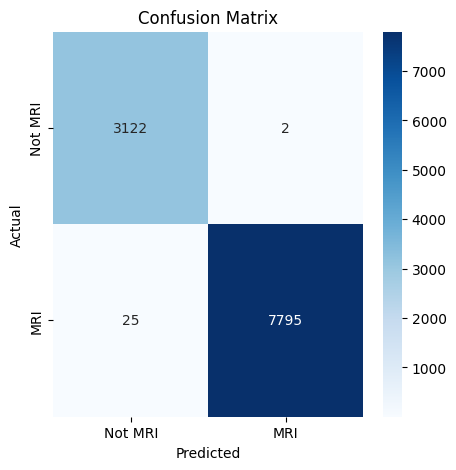

In [42]:
y_true = np.concatenate([y for x, y in test_ds_bin], axis=0).flatten()
y_pred_probs = model.predict(test_ds_bin, verbose=0)
y_pred = (y_pred_probs > 0.5).astype(int).flatten()

acc = accuracy_score(y_true, y_pred) * 100
precision_macro = precision_score(y_true, y_pred, average='macro') * 100
recall_macro = recall_score(y_true, y_pred, average='macro') * 100
f1_macro = f1_score(y_true, y_pred, average='macro') * 100
roc_auc = roc_auc_score(y_true, y_pred_probs)

print(f"\nTest Accuracy      : {acc:.3f}%")
print(f"Precision (macro)  : {precision_macro:.3f}%")
print(f"Recall (macro)     : {recall_macro:.3f}%")
print(f"F1-score (macro)   : {f1_macro:.3f}%")
print(f"ROC-AUC            : {roc_auc:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Not MRI", "MRI"],
    digits=3,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=["Not MRI", "MRI"],
    yticklabels=["Not MRI", "MRI"]
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion Matrix")
plt.show()


/tmp/ipykernel_55/1368305221.py:26: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  pred_label = int(pred_prob > 0.5)


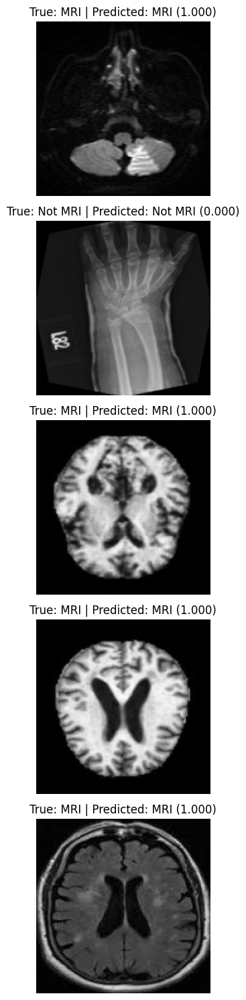

In [43]:
import matplotlib.pyplot as plt
import numpy as np
import random

# -------- دالة لعرض صور عشوائية مع التوقع --------
def show_random_predictions(dataset, model, class_names=["Not MRI", "MRI"], n_images=5):
    # 1️⃣ جمع كل الصور و labels في list
    all_images = []
    all_labels = []

    for batch_images, batch_labels in dataset:
        all_images.extend(batch_images.numpy())
        all_labels.extend(batch_labels.numpy())
    
    # 2️⃣ اختيار n صورة عشوائية
    indices = random.sample(range(len(all_images)), n_images)

    plt.figure(figsize=(15, 3*n_images))

    for i, idx in enumerate(indices, 1):
        img = all_images[idx]
        true_label = int(all_labels[idx])

        # توقع الصورة
        pred_prob = model.predict(np.expand_dims(img, axis=0), verbose=0)
        pred_label = int(pred_prob > 0.5)

        plt.subplot(n_images, 1, i)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"True: {class_names[true_label]} | Predicted: {class_names[pred_label]} ({pred_prob[0][0]:.3f})", fontsize=12)
    
    plt.tight_layout()
    plt.show()

# -------- تجربة الدالة على test dataset --------
show_random_predictions(test_ds_bin, model, n_images=5)

In [44]:
# حفظ نموذج Stage1
model.save("/kaggle/working/Stage1_MRI_vs_NotMRI.keras")
print("Stage1 model saved successfully!")

Stage1 model saved successfully!


In [45]:
import os
os.listdir("/kaggle/working/")

['best_binary_model.h5', '.virtual_documents', 'Stage1_MRI_vs_NotMRI.keras']

**Stage2**

In [46]:
import os
from pathlib import Path
import glob
import json
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

# ----------------- config -----------------
DATA_DIRS = [
    "/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/MRI/Epilepsy",
    "/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/MRI/Mild_Impairment_Alzheimer",
    "/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/MRI/Moderate_Impairment_Alzheimer",
    "/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/MRI/Normal",
    "/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/MRI/StrokeMR",
    "/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/MRI/Very_Mild_Impairment_Alzheimer",
    "/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/MRI/glioma_Tumor",
    "/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/MRI/meningioma_Tumor",
    "/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)/MRI/pituitary_Tumor"
]
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 101
TEST_RATIO = 0.15
VAL_RATIO = 0.10


# 1) collect PNG filepaths
#collect PNG filepaths
def collect_images(data_dirs):
    exts = ["*.png", "*.jpg", "*.jpeg", "*.PNG", "*.JPG", "*.JPEG"]
    rec = []

    for d in data_dirs:
        d = str(d)
        if not os.path.exists(d):
            print("Warning:", d, "not found")
            continue
        
        class_name = Path(d).name

        all_matches = []
        for ext in exts:
            all_matches += glob.glob(os.path.join(d, "**", ext), recursive=True)

        for p in all_matches:
            rec.append((p, class_name))

    return pd.DataFrame(rec, columns=["filepath", "label"])

# 2) label mapping (no shuffle here)
def prepare_labels(df):
    labels = sorted(df['label'].unique())
    label2idx = {l: i for i, l in enumerate(labels)}
    df['label_idx'] = df['label'].map(label2idx)
    return df, labels, label2idx


def df_to_tf_dataset(df, img_size=IMG_SIZE, batch_size=BATCH_SIZE,
                     shuffle=False, seed=SEED, num_classes=None):

    paths = df['filepath'].values.astype(str)
    labels = df['label_idx'].values.astype(np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df), seed=seed)

    def _map(path, label):
        img = tf.io.read_file(path)
    
    # استخدم الامتداد لتحديد الطريقة
        ext = tf.strings.lower(tf.strings.split(path, '.')[-1])
        img = tf.cond(
            tf.equal(ext, 'png'),
            lambda: tf.image.decode_png(img, channels=3),
            lambda: tf.image.decode_jpeg(img, channels=3)
        )

        img = tf.image.resize(img, img_size)
        img = tf.cast(img, tf.float32) / 255.0
        label_ohe = tf.one_hot(label, depth=num_classes)
        return img, label_ohe

    ds = ds.map(_map, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

In [47]:
df = collect_images(DATA_DIRS)
print("Total PNG images found:", len(df))

df, labels, label2idx = prepare_labels(df)


df, labels, label2idx = prepare_labels(df)
print("Classes:", labels)

print(df['label'].value_counts())

Total PNG images found: 39100
Classes: ['Epilepsy', 'Mild_Impairment_Alzheimer', 'Moderate_Impairment_Alzheimer', 'Normal', 'StrokeMR', 'Very_Mild_Impairment_Alzheimer', 'glioma_Tumor', 'meningioma_Tumor', 'pituitary_Tumor']
label
Normal                            7500
glioma_Tumor                      6500
StrokeMR                          5000
Moderate_Impairment_Alzheimer     4200
Mild_Impairment_Alzheimer         3800
Very_Mild_Impairment_Alzheimer    3400
meningioma_Tumor                  3200
Epilepsy                          3000
pituitary_Tumor                   2500
Name: count, dtype: int64


In [48]:
print("Class order (sorted):")
for idx in sorted(label2idx.values()):
    print(f"{idx} → {[k for k, v in label2idx.items() if v == idx][0]}")

Class order (sorted):
0 → Epilepsy
1 → Mild_Impairment_Alzheimer
2 → Moderate_Impairment_Alzheimer
3 → Normal
4 → StrokeMR
5 → Very_Mild_Impairment_Alzheimer
6 → glioma_Tumor
7 → meningioma_Tumor
8 → pituitary_Tumor


In [49]:
from sklearn.model_selection import train_test_split

# 1) Train + Temp (which later will be split into val + test)
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,       # 30% -> (val + test)
    stratify=df['label'], # stratify = maintain class balance
    random_state=42
)

# 2) Temp → Validation + Test (each = 15%)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,       # half temp -> test
    stratify=temp_df['label'],
    random_state=42
)

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)


import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB5
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

NUM_CLASSES = len(df['label'].unique())

train_ds = df_to_tf_dataset(train_df, img_size=(224,224), batch_size=32, shuffle=True, num_classes=NUM_CLASSES)
val_ds   = df_to_tf_dataset(val_df,   img_size=(224,224), batch_size=32, shuffle=False, num_classes=NUM_CLASSES)
test_ds  = df_to_tf_dataset(test_df,  img_size=(224,224), batch_size=32, shuffle=False, num_classes=NUM_CLASSES)

Train: (27370, 3)
Val: (5865, 3)
Test: (5865, 3)


**EfficientNetB5**

In [50]:
base_model = EfficientNetB5(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)
base_model.trainable = False 


from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras import regularizers

x = base_model.output
x = GlobalAveragePooling2D()(x)

x = BatchNormalization()(x)

x = Dropout(0.6)(x)

x = Dense(
    512,
    activation='relu',
    kernel_regularizer=regularizers.l2(1e-4)
)(x)
x = Dropout(0.5)(x)
output = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)



model.compile(
    optimizer=Adam(learning_rate=1e-4,clipvalue=1.0),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)
model.summary()

EPOCHS=15
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

115263384/115263384 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer_4[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │      1,296 │ stem_conv_pad[0]… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        192 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        432 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        192 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 48)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 48)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 12)  │        588 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 48)  │        624 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 48)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │      1,152 │ block1a_se_excit

 Total params: 29,575,424 (112.82 MB)

 Trainable params: 1,057,801 (4.04 MB)

 Non-trainable params: 28,517,623 (108.79 MB)

Epoch 1/15
856/856 ━━━━━━━━━━━━━━━━━━━━ 225s 191ms/step - accuracy: 0.1622 - loss: 3.1023 - val_accuracy: 0.3345 - val_loss: 1.9762
Epoch 2/15
856/856 ━━━━━━━━━━━━━━━━━━━━ 94s 110ms/step - accuracy: 0.2034 - loss: 2.6702 - val_accuracy: 0.3234 - val_loss: 1.9306
Epoch 3/15
856/856 ━━━━━━━━━━━━━━━━━━━━ 94s 110ms/step - accuracy: 0.2192 - loss: 2.4509 - val_accuracy: 0.3371 - val_loss: 1.9134
Epoch 4/15
856/856 ━━━━━━━━━━━━━━━━━━━━ 95s 110ms/step - accuracy: 0.2307 - loss: 2.3440 - val_accuracy: 0.3736 - val_loss: 1.8934
Epoch 5/15
856/856 ━━━━━━━━━━━━━━━━━━━━ 95s 110ms/step - accuracy: 0.2436 - loss: 2.2425 - val_accuracy: 0.3678 - val_loss: 1.9128
Epoch 6/15
856/856 ━━━━━━━━━━━━━━━━━━━━ 95s 111ms/step - accuracy: 0.2443 - loss: 2.1893 - val_accuracy: 0.3702 - val_loss: 1.9153
Epoch 7/15
856/856 ━━━━━━━━━━━━━━━━━━━━ 94s 110ms/step - accuracy: 0.2485 - loss: 2.1429 - val_accuracy: 0.3621 - val_loss: 1.9151
Epoch 8/15
856/856 ━━━━━━━━━━━━━━━━━━━━ 95s 110ms/step - accuracy: 0.2619 - loss: 

In [51]:
test_loss, test_acc = model.evaluate(test_ds)
print("Test Accuracy:", test_acc)

184/184 ━━━━━━━━━━━━━━━━━━━━ 17s 90ms/step - accuracy: 0.3372 - loss: 1.8974
Test Accuracy: 0.35140666365623474


In [52]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

# ---------------- CALLBACKS ----------------
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=6,              
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    'best_densenet121_finetune.h5',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.3,              
    patience=5,
    min_lr=1e-7,
    verbose=1
)


callbacks = [early_stop, checkpoint, reduce_lr]

# ---------------- FINE-TUNING ----------------
# فك تجميد آخر 100 طبقة فقط
base_model.trainable = True
for layer in base_model.layers[:-700]:
    layer.trainable = False

print("Trainable layers:", sum([layer.trainable for layer in base_model.layers]))
print("Total layers:", len(base_model.layers))

# ---------------- COMPILE ----------------
model.compile(
    optimizer=Adam(learning_rate=1e-5),   # أعلى من 5e-6 لأنه stable مع FT
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


# ---------------- TRAINING ----------------
history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,                  
    callbacks=callbacks,
    verbose=1
)

Trainable layers: 577
Total layers: 577
Epoch 1/50


2026-02-28 14:17:33.850859: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 14:17:34.041580: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 14:17:34.431216: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 14:17:34.627702: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 14:17:35.125255: E external/local_xla/xla/stream_

855/856 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step - accuracy: 0.3416 - loss: 1.7572

2026-02-28 14:24:39.049197: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 14:24:39.236396: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 14:24:39.568604: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 14:24:39.759552: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 14:24:40.121309: E external/local_xla/xla/stream_

856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.3417 - loss: 1.7569
Epoch 1: val_loss improved from inf to 1.38329, saving model to best_densenet121_finetune.h5


856/856 ━━━━━━━━━━━━━━━━━━━━ 674s 557ms/step - accuracy: 0.3419 - loss: 1.7566 - val_accuracy: 0.5748 - val_loss: 1.3833 - learning_rate: 1.0000e-05
Epoch 2/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 379ms/step - accuracy: 0.6483 - loss: 0.9840
Epoch 2: val_loss improved from 1.38329 to 0.74342, saving model to best_densenet121_finetune.h5


... (4 outputs left out)

856/856 ━━━━━━━━━━━━━━━━━━━━ 339s 396ms/step - accuracy: 0.9408 - loss: 0.2287 - val_accuracy: 0.9236 - val_loss: 0.2693 - learning_rate: 1.0000e-05
Epoch 12/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step - accuracy: 0.9493 - loss: 0.2071
Epoch 12: val_loss did not improve from 0.26928
856/856 ━━━━━━━━━━━━━━━━━━━━ 335s 391ms/step - accuracy: 0.9493 - loss: 0.2071 - val_accuracy: 0.8812 - val_loss: 0.4058 - learning_rate: 1.0000e-05
Epoch 13/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step - accuracy: 0.9603 - loss: 0.1800
Epoch 13: val_loss did not improve from 0.26928
856/856 ━━━━━━━━━━━━━━━━━━━━ 335s 391ms/step - accuracy: 0.9603 - loss: 0.1800 - val_accuracy: 0.9219 - val_loss: 0.2891 - learning_rate: 1.0000e-05
Epoch 14/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step - accuracy: 0.9648 - loss: 0.1735
Epoch 14: val_loss improved from 0.26928 to 0.23236, saving model to best_densenet121_finetune.h5


856/856 ━━━━━━━━━━━━━━━━━━━━ 338s 395ms/step - accuracy: 0.9648 - loss: 0.1734 - val_accuracy: 0.9432 - val_loss: 0.2324 - learning_rate: 1.0000e-05
Epoch 15/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - accuracy: 0.9714 - loss: 0.1522
Epoch 15: val_loss did not improve from 0.23236
856/856 ━━━━━━━━━━━━━━━━━━━━ 336s 392ms/step - accuracy: 0.9714 - loss: 0.1522 - val_accuracy: 0.8646 - val_loss: 0.4478 - learning_rate: 1.0000e-05
Epoch 16/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - accuracy: 0.9730 - loss: 0.1471
Epoch 16: val_loss did not improve from 0.23236
856/856 ━━━━━━━━━━━━━━━━━━━━ 336s 393ms/step - accuracy: 0.9730 - loss: 0.1471 - val_accuracy: 0.9086 - val_loss: 0.3374 - learning_rate: 1.0000e-05
Epoch 17/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step - accuracy: 0.9764 - loss: 0.1372
Epoch 17: val_loss improved from 0.23236 to 0.21535, saving model to best_densenet121_finetune.h5


856/856 ━━━━━━━━━━━━━━━━━━━━ 337s 394ms/step - accuracy: 0.9764 - loss: 0.1372 - val_accuracy: 0.9553 - val_loss: 0.2153 - learning_rate: 1.0000e-05
Epoch 18/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step - accuracy: 0.9826 - loss: 0.1199
Epoch 18: val_loss improved from 0.21535 to 0.20389, saving model to best_densenet121_finetune.h5


856/856 ━━━━━━━━━━━━━━━━━━━━ 337s 394ms/step - accuracy: 0.9826 - loss: 0.1199 - val_accuracy: 0.9611 - val_loss: 0.2039 - learning_rate: 1.0000e-05
Epoch 19/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 372ms/step - accuracy: 0.9841 - loss: 0.1164
Epoch 19: val_loss did not improve from 0.20389
856/856 ━━━━━━━━━━━━━━━━━━━━ 335s 391ms/step - accuracy: 0.9841 - loss: 0.1164 - val_accuracy: 0.9424 - val_loss: 0.2642 - learning_rate: 1.0000e-05
Epoch 20/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step - accuracy: 0.9856 - loss: 0.1108
Epoch 20: val_loss did not improve from 0.20389
856/856 ━━━━━━━━━━━━━━━━━━━━ 335s 391ms/step - accuracy: 0.9856 - loss: 0.1108 - val_accuracy: 0.9315 - val_loss: 0.2998 - learning_rate: 1.0000e-05
Epoch 21/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 374ms/step - accuracy: 0.9860 - loss: 0.1073
Epoch 21: val_loss did not improve from 0.20389
856/856 ━━━━━━━━━━━━━━━━━━━━ 336s 393ms/step - accuracy: 0.9860 - loss: 0.1073 - val_accuracy: 0.9344 - val_loss: 0.2893 - learning_rate: 1.00

Train Accuracy: 99.1195%
Validation Accuracy: 96.2148%
Best Validation Loss: 0.2039


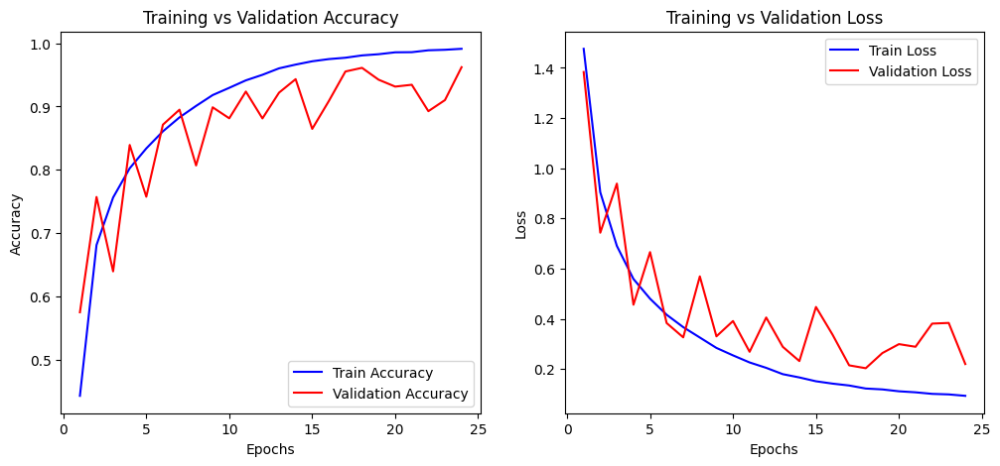

184/184 ━━━━━━━━━━━━━━━━━━━━ 42s 157ms/step


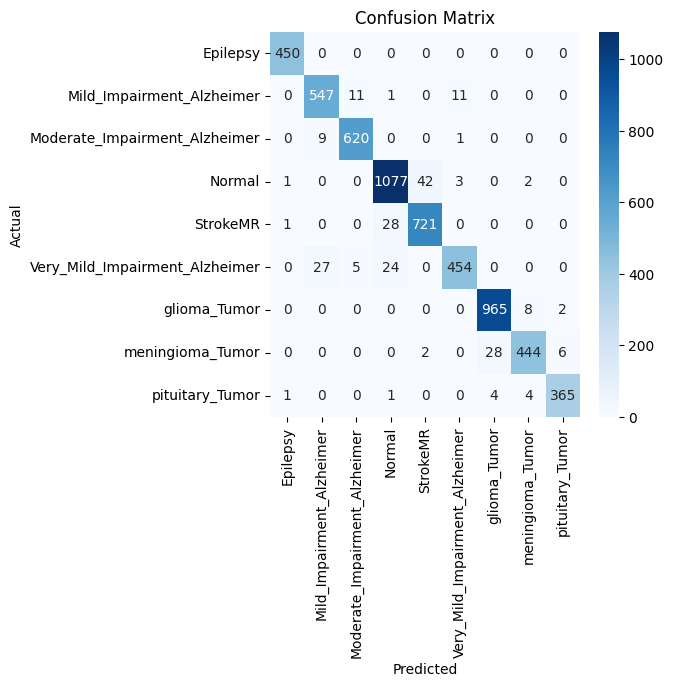

184/184 ━━━━━━━━━━━━━━━━━━━━ 16s 87ms/step
Test samples: 5865
Test Accuracy      : 96.215%
Precision (macro)  : 96.501%
Recall (macro)     : 96.008%
F1-score (macro)   : 96.226%

Classification Report (%):

              precision    recall  f1-score   support

           0      0.993     1.000     0.997       450
           1      0.938     0.960     0.949       570
           2      0.975     0.984     0.979       630
           3      0.952     0.957     0.955      1125
           4      0.942     0.961     0.952       750
           5      0.968     0.890     0.927       510
           6      0.968     0.990     0.979       975
           7      0.969     0.925     0.947       480
           8      0.979     0.973     0.976       375

    accuracy                          0.962      5865
   macro avg      0.965     0.960     0.962      5865
weighted avg      0.962     0.962     0.962      5865


Final validation accuracy: 34.731%
Final validation loss   : 1.882


In [53]:
import matplotlib.pyplot as plt

# استخرج الـ metrics من history
acc = history_ft.history['accuracy']
val_acc = history_ft.history['val_accuracy']
loss = history_ft.history['loss']
val_loss = history_ft.history['val_loss']

epochs = range(1, len(acc)+1)

# -------- حساب أعلى دقة --------
best_train_acc = max(acc)
best_val_acc = max(val_acc)
best_val_loss = min(val_loss)

print(f"Train Accuracy: {best_train_acc*100:.4f}%")
print(f"Validation Accuracy: {best_val_acc*100:.4f}%")
print(f"Best Validation Loss: {best_val_loss:.4f}")

# -------- رسم Accuracy و Loss --------
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs, acc, 'b-', label='Train Accuracy')
plt.plot(epochs, val_acc, 'r-', label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs, loss, 'b-', label='Train Loss')
plt.plot(epochs, val_loss, 'r-', label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

#----------------------------------------------------------------------


from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

class_names = labels  # استخدم اللي طلعت من prepare_labels

# استخراج y_true
y_true = np.concatenate([y for x, y in test_ds], axis=0).argmax(axis=1)

# استخراج y_pred
y_pred = np.argmax(model.predict(test_ds), axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion Matrix")
plt.show()

#----------------------------------------------------------------------


# Predict probabilities on the entire test set
y_pred_probs = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)

# Extract true labels from test_ds (one-hot -> idx)
# Concatenate batches to a single array
y_true_ohe = np.concatenate([y for x, y in test_ds], axis=0)
y_true = np.argmax(y_true_ohe, axis=1)

print("Test samples:", len(y_true))



# Cell 5: Metrics (sklearn)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

acc = accuracy_score(y_true, y_pred) * 100
precision_macro = precision_score(y_true, y_pred, average='macro') * 100
recall_macro = recall_score(y_true, y_pred, average='macro') * 100
f1_macro = f1_score(y_true, y_pred, average='macro') * 100

print(f"Test Accuracy      : {acc:.3f}%")
print(f"Precision (macro)  : {precision_macro:.3f}%")
print(f"Recall (macro)     : {recall_macro:.3f}%")
print(f"F1-score (macro)   : {f1_macro:.3f}%")

print("\nClassification Report (%):\n")

# نضرب التقرير كله في 100 و نخليه 3 أرقام عشرية
print(
    classification_report(
        y_true,
        y_pred,
        digits=3,
        zero_division=0
    )
)

# Final validation accuracy & loss from history
val_acc_list = history.history.get('val_accuracy', [])
val_loss_list = history.history.get('val_loss', [])

if val_acc_list:
    print(f"\nFinal validation accuracy: {val_acc_list[-1]*100:.3f}%")
if val_loss_list:
    print(f"Final validation loss   : {val_loss_list[-1]:.3f}")


In [54]:
model.save("/kaggle/working/EfficientNetB5_for_ensemble.keras")

In [55]:
import os
os.listdir("/kaggle/working/")

['best_binary_model.h5',
 '.virtual_documents',
 'best_densenet121_finetune.h5',
 'EfficientNetB5_for_ensemble.keras',
 'Stage1_MRI_vs_NotMRI.keras']

**DenseNet121**

In [56]:
import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

base_model = DenseNet121(
    weights='imagenet',
    include_top=False,   # نلغي الطبقة الأخيرة علشان نعمل fine-tuning
    input_shape=(224,224,3)
)

# نجمّد الـ base_model أولًا
base_model.trainable = False



from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras import regularizers

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.6)(x)                  # زيادة Dropout لتقليل Overfitting
x = Dense(512, activation='relu',kernel_regularizer=regularizers.l2(1e-4,))(x) # طبقة Dense إضافية intermediate
x = Dropout(0.5)(x)                  # Dropout ثاني قبل final output
output = Dense(NUM_CLASSES, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)



model.compile(
    optimizer=Adam(learning_rate=3e-4,clipvalue=1.0),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)
model.summary()


EPOCHS = 10  # ممكن تزود بعد التجربة
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_5       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 230, 230,  │          0 │ input_layer_5[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,566,921 (28.87 MB)

 Trainable params: 529,417 (2.02 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

Epoch 1/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 130s 119ms/step - accuracy: 0.3424 - loss: 2.1896 - val_accuracy: 0.6094 - val_loss: 1.4256
Epoch 2/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 62s 72ms/step - accuracy: 0.5119 - loss: 1.4820 - val_accuracy: 0.6864 - val_loss: 1.2901
Epoch 3/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 62s 72ms/step - accuracy: 0.5642 - loss: 1.3898 - val_accuracy: 0.7038 - val_loss: 1.2214
Epoch 4/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 62s 72ms/step - accuracy: 0.5852 - loss: 1.3476 - val_accuracy: 0.7257 - val_loss: 1.1705
Epoch 5/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 61s 71ms/step - accuracy: 0.6017 - loss: 1.3188 - val_accuracy: 0.7320 - val_loss: 1.1601
Epoch 6/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 61s 72ms/step - accuracy: 0.6187 - loss: 1.2923 - val_accuracy: 0.7555 - val_loss: 1.1441
Epoch 7/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 61s 71ms/step - accuracy: 0.6273 - loss: 1.2749 - val_accuracy: 0.7528 - val_loss: 1.1017
Epoch 8/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 61s 71ms/step - accuracy: 0.6385 - loss: 1.2548 

In [57]:
test_loss, test_acc = model.evaluate(test_ds)
print("Test Accuracy:", test_acc)

184/184 ━━━━━━━━━━━━━━━━━━━━ 11s 62ms/step - accuracy: 0.7694 - loss: 1.0559
Test Accuracy: 0.7660698890686035


In [58]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# ---------------- CALLBACKS ----------------
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    'best_densenet121_finetune.h5',  # اسم مختلف عن المرة الأولى
    monitor='val_loss',
    save_best_only=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-7
)

callbacks = [early_stop, checkpoint, reduce_lr]

# ---------------- FINE-TUNING ----------------
# فك تجميد آخر layers من DenseNet121
base_model.trainable = True
for layer in base_model.layers[:-500]:
    layer.trainable = False

# Compile تاني
model.compile(
    optimizer=Adam(3e-5),  # learning rate أقل
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train مع callbacks
history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=callbacks
)

Epoch 1/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 290ms/step - accuracy: 0.6399 - loss: 0.9747

856/856 ━━━━━━━━━━━━━━━━━━━━ 458s 331ms/step - accuracy: 0.6400 - loss: 0.9744 - val_accuracy: 0.8505 - val_loss: 0.3875 - learning_rate: 3.0000e-05
Epoch 2/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.8413 - loss: 0.4293

856/856 ━━━━━━━━━━━━━━━━━━━━ 155s 181ms/step - accuracy: 0.8413 - loss: 0.4293 - val_accuracy: 0.8730 - val_loss: 0.3229 - learning_rate: 3.0000e-05
Epoch 3/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.8849 - loss: 0.3193

856/856 ━━━━━━━━━━━━━━━━━━━━ 155s 181ms/step - accuracy: 0.8849 - loss: 0.3193 - val_accuracy: 0.9043 - val_loss: 0.2721 - learning_rate: 3.0000e-05
Epoch 4/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.9139 - loss: 0.2524

856/856 ━━━━━━━━━━━━━━━━━━━━ 155s 181ms/step - accuracy: 0.9139 - loss: 0.2524 - val_accuracy: 0.9173 - val_loss: 0.2301 - learning_rate: 3.0000e-05
Epoch 5/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 153s 179ms/step - accuracy: 0.9441 - loss: 0.1809 - val_accuracy: 0.9091 - val_loss: 0.2613 - learning_rate: 3.0000e-05
Epoch 6/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 153s 179ms/step - accuracy: 0.9592 - loss: 0.1441 - val_accuracy: 0.9246 - val_loss: 0.2321 - learning_rate: 3.0000e-05
Epoch 7/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.9737 - loss: 0.1122

856/856 ━━━━━━━━━━━━━━━━━━━━ 155s 180ms/step - accuracy: 0.9737 - loss: 0.1122 - val_accuracy: 0.9451 - val_loss: 0.1975 - learning_rate: 3.0000e-05
Epoch 8/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 153s 178ms/step - accuracy: 0.9819 - loss: 0.0893 - val_accuracy: 0.9419 - val_loss: 0.2121 - learning_rate: 3.0000e-05
Epoch 9/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 152s 178ms/step - accuracy: 0.9833 - loss: 0.0829 - val_accuracy: 0.9403 - val_loss: 0.2346 - learning_rate: 3.0000e-05
Epoch 10/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 154s 180ms/step - accuracy: 0.9875 - loss: 0.0704 - val_accuracy: 0.9214 - val_loss: 0.3528 - learning_rate: 3.0000e-05
Epoch 11/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.9922 - loss: 0.0613

856/856 ━━━━━━━━━━━━━━━━━━━━ 154s 180ms/step - accuracy: 0.9922 - loss: 0.0612 - val_accuracy: 0.9657 - val_loss: 0.1503 - learning_rate: 6.0000e-06
Epoch 12/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step - accuracy: 0.9963 - loss: 0.0461

856/856 ━━━━━━━━━━━━━━━━━━━━ 154s 180ms/step - accuracy: 0.9963 - loss: 0.0461 - val_accuracy: 0.9662 - val_loss: 0.1489 - learning_rate: 6.0000e-06
Epoch 13/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 154s 179ms/step - accuracy: 0.9971 - loss: 0.0429 - val_accuracy: 0.9657 - val_loss: 0.1547 - learning_rate: 6.0000e-06
Epoch 14/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 153s 178ms/step - accuracy: 0.9978 - loss: 0.0406 - val_accuracy: 0.9664 - val_loss: 0.1496 - learning_rate: 6.0000e-06
Epoch 15/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 152s 178ms/step - accuracy: 0.9985 - loss: 0.0390 - val_accuracy: 0.9698 - val_loss: 0.1552 - learning_rate: 6.0000e-06
Epoch 16/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 152s 178ms/step - accuracy: 0.9986 - loss: 0.0394 - val_accuracy: 0.9671 - val_loss: 0.1557 - learning_rate: 1.2000e-06
Epoch 17/50
856/856 ━━━━━━━━━━━━━━━━━━━━ 152s 177ms/step - accuracy: 0.9985 - loss: 0.0386 - val_accuracy: 0.9683 - val_loss: 0.1546 - learning_rate: 1.2000e-06


Train Accuracy: 99.8575%
Validation Accuracy: 96.9821%
Best Validation Loss: 0.1489


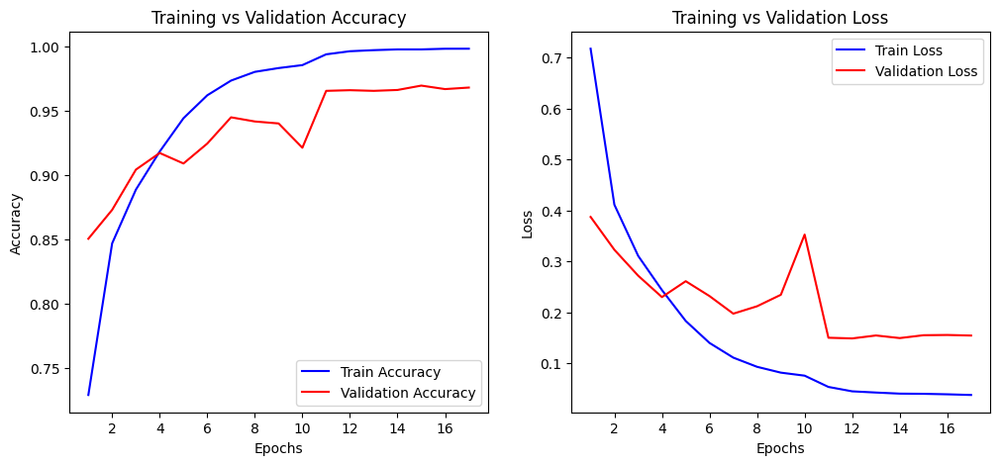

Precision (Macro): 96.54%
Recall (Macro): 96.70%
F1-score (Macro): 96.61%
184/184 ━━━━━━━━━━━━━━━━━━━━ 34s 124ms/step


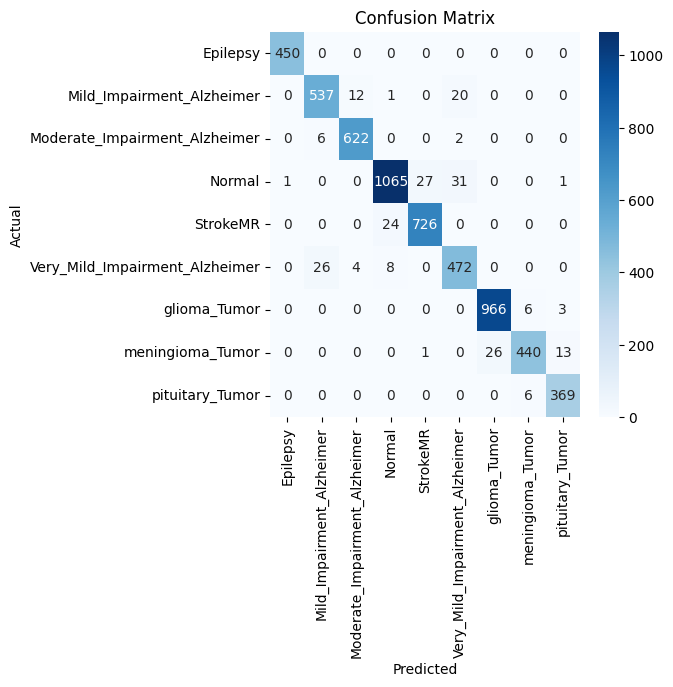

184/184 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step
Test samples: 5865
Test Accuracy      : 96.283%
Precision (macro)  : 96.128%
Recall (macro)     : 96.233%
F1-score (macro)   : 96.164%

Classification Report (%):

              precision    recall  f1-score   support

           0      0.998     1.000     0.999       450
           1      0.944     0.942     0.943       570
           2      0.975     0.987     0.981       630
           3      0.970     0.947     0.958      1125
           4      0.963     0.968     0.965       750
           5      0.899     0.925     0.912       510
           6      0.974     0.991     0.982       975
           7      0.973     0.917     0.944       480
           8      0.956     0.984     0.970       375

    accuracy                          0.963      5865
   macro avg      0.961     0.962     0.962      5865
weighted avg      0.963     0.963     0.963      5865


Final validation accuracy: 78.090%
Final validation loss   : 1.049


In [59]:
import matplotlib.pyplot as plt

# استخرج الـ metrics من history
acc = history_ft.history['accuracy']
val_acc = history_ft.history['val_accuracy']
loss = history_ft.history['loss']
val_loss = history_ft.history['val_loss']

epochs = range(1, len(acc)+1)

# -------- حساب أعلى دقة --------
best_train_acc = max(acc)
best_val_acc = max(val_acc)
best_val_loss = min(val_loss)

print(f"Train Accuracy: {best_train_acc*100:.4f}%")
print(f"Validation Accuracy: {best_val_acc*100:.4f}%")
print(f"Best Validation Loss: {best_val_loss:.4f}")

# -------- رسم Accuracy و Loss --------
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs, acc, 'b-', label='Train Accuracy')
plt.plot(epochs, val_acc, 'r-', label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs, loss, 'b-', label='Train Loss')
plt.plot(epochs, val_loss, 'r-', label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

#----------------------------------------------------------------------

import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# -------- استخراج y_true و y_pred من val_ds --------
y_true = []
y_pred = []

for batch_images, batch_labels in val_ds:
    # true labels
    y_true.extend(np.argmax(batch_labels.numpy(), axis=1))

    # predicted labels
    preds = model.predict(batch_images,verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# -------- Precision, Recall, F1-Score (Macro فقط) --------
precision_macro = precision_score(y_true, y_pred, average='macro')
recall_macro = recall_score(y_true, y_pred, average='macro')
f1_macro = f1_score(y_true, y_pred, average='macro')

# -------- Print results --------
print(f"Precision (Macro): {precision_macro*100:.2f}%")
print(f"Recall (Macro): {recall_macro*100:.2f}%")
print(f"F1-score (Macro): {f1_macro*100:.2f}%")

#----------------------------------------------------------------------

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

class_names = labels  # استخدم اللي طلعت من prepare_labels

# استخراج y_true
y_true = np.concatenate([y for x, y in test_ds], axis=0).argmax(axis=1)

# استخراج y_pred
y_pred = np.argmax(model.predict(test_ds), axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion Matrix")
plt.show()

#----------------------------------------------------------------------

# Predict probabilities on the entire test set
y_pred_probs = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)

# Extract true labels from test_ds (one-hot -> idx)
# Concatenate batches to a single array
y_true_ohe = np.concatenate([y for x, y in test_ds], axis=0)
y_true = np.argmax(y_true_ohe, axis=1)

print("Test samples:", len(y_true))

#----------------------------------------------------------------------

# Cell 5: Metrics (sklearn)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

acc = accuracy_score(y_true, y_pred) * 100
precision_macro = precision_score(y_true, y_pred, average='macro') * 100
recall_macro = recall_score(y_true, y_pred, average='macro') * 100
f1_macro = f1_score(y_true, y_pred, average='macro') * 100

print(f"Test Accuracy      : {acc:.3f}%")
print(f"Precision (macro)  : {precision_macro:.3f}%")
print(f"Recall (macro)     : {recall_macro:.3f}%")
print(f"F1-score (macro)   : {f1_macro:.3f}%")

print("\nClassification Report (%):\n")

# نضرب التقرير كله في 100 و نخليه 3 أرقام عشرية
print(
    classification_report(
        y_true,
        y_pred,
        digits=3,
        zero_division=0
    )
)

# Final validation accuracy & loss from history
val_acc_list = history.history.get('val_accuracy', [])
val_loss_list = history.history.get('val_loss', [])

if val_acc_list:
    print(f"\nFinal validation accuracy: {val_acc_list[-1]*100:.3f}%")
if val_loss_list:
    print(f"Final validation loss   : {val_loss_list[-1]:.3f}")

In [60]:
model.save("/kaggle/working/DenseNet121_for_ensemble.keras")

In [61]:
import os
os.listdir("/kaggle/working/")

['DenseNet121_for_ensemble.keras',
 'best_binary_model.h5',
 '.virtual_documents',
 'best_densenet121_finetune.h5',
 'EfficientNetB5_for_ensemble.keras',
 'Stage1_MRI_vs_NotMRI.keras']

**EfficientNetV2S**

In [62]:
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras import layers, models
from tensorflow.keras import regularizers
import tensorflow as tf

num_classes = 9

base_model = EfficientNetV2S(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False  # freeze

inputs = layers.Input(shape=(224, 224, 3))
x = tf.keras.applications.efficientnet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = Dense(512, activation='relu',kernel_regularizer=regularizers.l2(1e-4,))(x) # طبقة Dense إضافية intermediate
x = Dropout(0.4)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = models.Model(inputs, outputs)

#----------------------------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(3e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

#----------------------------------------------------------------------

EPOCHS = 10  # ممكن تزود بعد التجربة
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 167s 139ms/step - accuracy: 0.3442 - loss: 1.7448 - val_accuracy: 0.5192 - val_loss: 1.3195
Epoch 2/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 66s 77ms/step - accuracy: 0.4364 - loss: 1.4513 - val_accuracy: 0.4946 - val_loss: 1.3002
Epoch 3/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 66s 77ms/step - accuracy: 0.4538 - loss: 1.3888 - val_accuracy: 0.5342 - val_loss: 1.2175
Epoch 4/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 67s 78ms/step - accuracy: 0.4746 - loss: 1.3480 - val_accuracy: 0.5306 - val_loss: 1.1929
Epoch 5/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 66s 77ms/step - accuracy: 0.4857 - loss: 1.3236 - val_accuracy: 0.5579 - val_loss: 1.1770
Epoch 6/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 66s 77ms/step - accuracy: 0.4894 - loss: 1.3162 - val_accuracy: 0.5724 - val_loss: 1.1474
Epoch 7/10
856/856 ━━━━━━━━━━━━━━━━━━━━ 66s 77ms/step - accuracy: 0.4934 - loss: 1.2926 - val_accuracy: 0.5666 - val_loss: 1.1440
Epoch 8/10
856/856 ━━━━━━━━━━━━━━━━━━

In [63]:
test_loss, test_acc = model.evaluate(test_ds)
print("Test Accuracy:", test_acc)

184/184 ━━━━━━━━━━━━━━━━━━━━ 12s 63ms/step - accuracy: 0.5913 - loss: 1.1123
Test Accuracy: 0.5971014499664307


In [64]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# ---------------- CALLBACKS ----------------
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    'best_densenet121_finetune.h5',  # اسم مختلف عن المرة الأولى
    monitor='val_loss',
    save_best_only=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-7
)

callbacks = [early_stop, checkpoint, reduce_lr]

# ---------------- FINE-TUNING ----------------
base_model.trainable = True
for layer in base_model.layers[:-500]:
    layer.trainable = False

# Compile تاني
model.compile(
    optimizer=Adam(5e-5),  # learning rate أقل
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train مع callbacks
history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=80,
    callbacks=callbacks
)

Epoch 1/80


2026-02-28 17:54:11.521308: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 17:54:11.721403: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 17:54:12.273898: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 17:54:12.499958: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


855/856 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - accuracy: 0.6178 - loss: 1.1621

2026-02-28 17:58:08.420903: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 17:58:08.617423: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 17:58:09.123560: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-02-28 17:58:09.347712: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 286ms/step - accuracy: 0.6180 - loss: 1.1616

856/856 ━━━━━━━━━━━━━━━━━━━━ 419s 324ms/step - accuracy: 0.6181 - loss: 1.1612 - val_accuracy: 0.8769 - val_loss: 0.3477 - learning_rate: 5.0000e-05
Epoch 2/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 200ms/step - accuracy: 0.8544 - loss: 0.4228

... (7 outputs left out)

856/856 ━━━━━━━━━━━━━━━━━━━━ 181s 211ms/step - accuracy: 0.9958 - loss: 0.0582 - val_accuracy: 0.9816 - val_loss: 0.1215 - learning_rate: 2.0000e-06
Epoch 17/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 179s 209ms/step - accuracy: 0.9967 - loss: 0.0561 - val_accuracy: 0.9824 - val_loss: 0.1223 - learning_rate: 2.0000e-06
Epoch 18/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 179s 209ms/step - accuracy: 0.9966 - loss: 0.0558 - val_accuracy: 0.9824 - val_loss: 0.1253 - learning_rate: 2.0000e-06
Epoch 19/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.9973 - loss: 0.0541

856/856 ━━━━━━━━━━━━━━━━━━━━ 181s 211ms/step - accuracy: 0.9973 - loss: 0.0541 - val_accuracy: 0.9826 - val_loss: 0.1193 - learning_rate: 2.0000e-06
Epoch 20/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 180s 210ms/step - accuracy: 0.9977 - loss: 0.0530 - val_accuracy: 0.9828 - val_loss: 0.1209 - learning_rate: 2.0000e-06
Epoch 21/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 179s 209ms/step - accuracy: 0.9974 - loss: 0.0533 - val_accuracy: 0.9823 - val_loss: 0.1218 - learning_rate: 2.0000e-06
Epoch 22/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 0.9968 - loss: 0.0534

856/856 ━━━━━━━━━━━━━━━━━━━━ 181s 211ms/step - accuracy: 0.9968 - loss: 0.0534 - val_accuracy: 0.9823 - val_loss: 0.1172 - learning_rate: 2.0000e-06
Epoch 23/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 179s 209ms/step - accuracy: 0.9969 - loss: 0.0539 - val_accuracy: 0.9833 - val_loss: 0.1233 - learning_rate: 2.0000e-06
Epoch 24/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 179s 209ms/step - accuracy: 0.9969 - loss: 0.0529 - val_accuracy: 0.9828 - val_loss: 0.1177 - learning_rate: 2.0000e-06
Epoch 25/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 179s 209ms/step - accuracy: 0.9972 - loss: 0.0523 - val_accuracy: 0.9835 - val_loss: 0.1186 - learning_rate: 2.0000e-06
Epoch 26/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.9973 - loss: 0.0527

856/856 ━━━━━━━━━━━━━━━━━━━━ 180s 211ms/step - accuracy: 0.9973 - loss: 0.0527 - val_accuracy: 0.9829 - val_loss: 0.1168 - learning_rate: 4.0000e-07
Epoch 27/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 179s 208ms/step - accuracy: 0.9976 - loss: 0.0506 - val_accuracy: 0.9836 - val_loss: 0.1252 - learning_rate: 4.0000e-07
Epoch 28/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 178s 208ms/step - accuracy: 0.9977 - loss: 0.0499 - val_accuracy: 0.9838 - val_loss: 0.1193 - learning_rate: 4.0000e-07
Epoch 29/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 178s 208ms/step - accuracy: 0.9979 - loss: 0.0507 - val_accuracy: 0.9843 - val_loss: 0.1197 - learning_rate: 4.0000e-07
Epoch 30/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 178s 208ms/step - accuracy: 0.9974 - loss: 0.0518 - val_accuracy: 0.9836 - val_loss: 0.1206 - learning_rate: 1.0000e-07
Epoch 31/80
856/856 ━━━━━━━━━━━━━━━━━━━━ 179s 209ms/step - accuracy: 0.9979 - loss: 0.0507 - val_accuracy: 0.9836 - val_loss: 0.1191 - learning_rate: 1.0000e-07


Train Accuracy: 99.8027%
Validation Accuracy: 98.4314%
Best Validation Loss: 0.1168


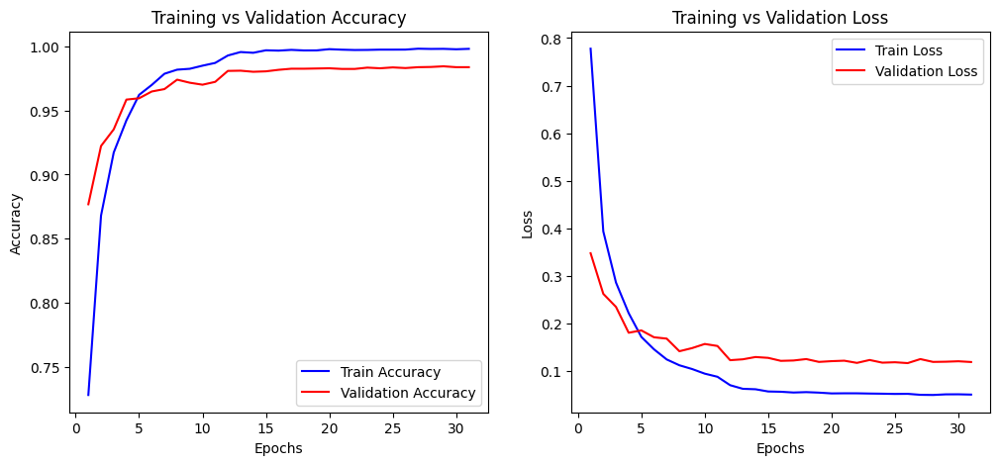

Precision (Macro): 98.33%
Recall (Macro): 98.26%
F1-score (Macro): 98.29%
184/184 ━━━━━━━━━━━━━━━━━━━━ 28s 106ms/step


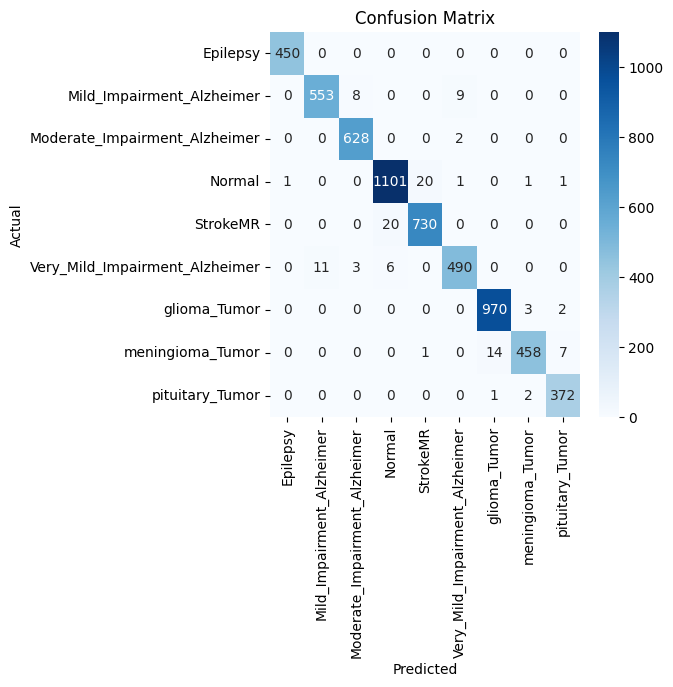

184/184 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step
Test samples: 5865
Test Accuracy      : 98.073%
Precision (macro)  : 98.131%
Recall (macro)     : 98.009%
F1-score (macro)   : 98.064%

Classification Report (%):

              precision    recall  f1-score   support

           0      0.998     1.000     0.999       450
           1      0.980     0.970     0.975       570
           2      0.983     0.997     0.990       630
           3      0.977     0.979     0.978      1125
           4      0.972     0.973     0.973       750
           5      0.976     0.961     0.968       510
           6      0.985     0.995     0.990       975
           7      0.987     0.954     0.970       480
           8      0.974     0.992     0.983       375

    accuracy                          0.981      5865
   macro avg      0.981     0.980     0.981      5865
weighted avg      0.981     0.981     0.981      5865


Final validation accuracy: 59.523%
Final validation loss   : 1.104


In [65]:
import matplotlib.pyplot as plt

# استخرج الـ metrics من history
acc = history_ft.history['accuracy']
val_acc = history_ft.history['val_accuracy']
loss = history_ft.history['loss']
val_loss = history_ft.history['val_loss']

epochs = range(1, len(acc)+1)

# -------- حساب أعلى دقة --------
best_train_acc = max(acc)
best_val_acc = max(val_acc)
best_val_loss = min(val_loss)

print(f"Train Accuracy: {best_train_acc*100:.4f}%")
print(f"Validation Accuracy: {best_val_acc*100:.4f}%")
print(f"Best Validation Loss: {best_val_loss:.4f}")

# -------- رسم Accuracy و Loss --------
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(epochs, acc, 'b-', label='Train Accuracy')
plt.plot(epochs, val_acc, 'r-', label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs, loss, 'b-', label='Train Loss')
plt.plot(epochs, val_loss, 'r-', label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

#----------------------------------------------------------------------

import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# -------- استخراج y_true و y_pred من val_ds --------
y_true = []
y_pred = []

for batch_images, batch_labels in val_ds:
    # true labels
    y_true.extend(np.argmax(batch_labels.numpy(), axis=1))

    # predicted labels
    preds = model.predict(batch_images,verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# -------- Precision, Recall, F1-Score (Macro فقط) --------
precision_macro = precision_score(y_true, y_pred, average='macro')
recall_macro = recall_score(y_true, y_pred, average='macro')
f1_macro = f1_score(y_true, y_pred, average='macro')

# -------- Print results --------
print(f"Precision (Macro): {precision_macro*100:.2f}%")
print(f"Recall (Macro): {recall_macro*100:.2f}%")
print(f"F1-score (Macro): {f1_macro*100:.2f}%")

#----------------------------------------------------------------------

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

class_names = labels  # استخدم اللي طلعت من prepare_labels

# استخراج y_true
y_true = np.concatenate([y for x, y in test_ds], axis=0).argmax(axis=1)

# استخراج y_pred
y_pred = np.argmax(model.predict(test_ds), axis=1)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(5,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title("Confusion Matrix")
plt.show()

#----------------------------------------------------------------------

# Predict probabilities on the entire test set
y_pred_probs = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_pred_probs, axis=1)

# Extract true labels from test_ds (one-hot -> idx)
# Concatenate batches to a single array
y_true_ohe = np.concatenate([y for x, y in test_ds], axis=0)
y_true = np.argmax(y_true_ohe, axis=1)

print("Test samples:", len(y_true))

#----------------------------------------------------------------------

# Cell 5: Metrics (sklearn)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

acc = accuracy_score(y_true, y_pred) * 100
precision_macro = precision_score(y_true, y_pred, average='macro') * 100
recall_macro = recall_score(y_true, y_pred, average='macro') * 100
f1_macro = f1_score(y_true, y_pred, average='macro') * 100

print(f"Test Accuracy      : {acc:.3f}%")
print(f"Precision (macro)  : {precision_macro:.3f}%")
print(f"Recall (macro)     : {recall_macro:.3f}%")
print(f"F1-score (macro)   : {f1_macro:.3f}%")

print("\nClassification Report (%):\n")

# نضرب التقرير كله في 100 و نخليه 3 أرقام عشرية
print(
    classification_report(
        y_true,
        y_pred,
        digits=3,
        zero_division=0
    )
)

# Final validation accuracy & loss from history
val_acc_list = history.history.get('val_accuracy', [])
val_loss_list = history.history.get('val_loss', [])

if val_acc_list:
    print(f"\nFinal validation accuracy: {val_acc_list[-1]*100:.3f}%")
if val_loss_list:
    print(f"Final validation loss   : {val_loss_list[-1]:.3f}")

In [66]:
model.save("/kaggle/working/EfficientNetV2S_for_ensemble.keras")

In [67]:
import os
os.listdir("/kaggle/working/")

['DenseNet121_for_ensemble.keras',
 'best_binary_model.h5',
 '.virtual_documents',
 'best_densenet121_finetune.h5',
 'EfficientNetB5_for_ensemble.keras',
 'Stage1_MRI_vs_NotMRI.keras',
 'EfficientNetV2S_for_ensemble.keras']

**Ensemble Learning**

In [69]:
from tensorflow.keras.models import load_model

model_EfficientNetB5 = load_model("EfficientNetB5_for_ensemble.keras")
model_DensNet = load_model("DenseNet121_for_ensemble.keras")
model_EfficientNetV2S = load_model("EfficientNetV2S_for_ensemble.keras")


preds1 = model_EfficientNetB5.predict(test_ds, verbose=0)
preds2 = model_DensNet.predict(test_ds, verbose=0)
preds3 = model_EfficientNetV2S.predict(test_ds, verbose=0)

avg_preds = (preds1 + preds2 + preds3) / 3

y_pred_ensemble = np.argmax(avg_preds, axis=1)

y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_true = np.argmax(y_true, axis=1)

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 512 variables whereas the saved optimizer has 1022 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 368 variables whereas the saved optimizer has 734 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 447 variables whereas the saved optimizer has 892 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


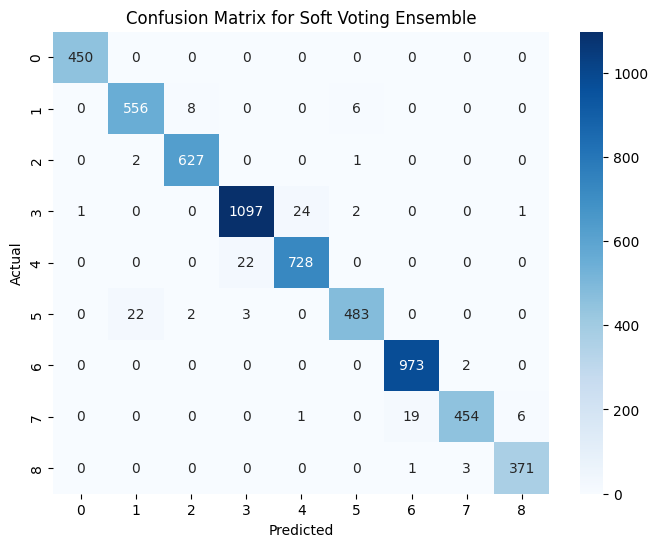

Soft Voting Ensemble Accuracy: 0.9785166240409208
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00       450
           1       0.96      0.98      0.97       570
           2       0.98      1.00      0.99       630
           3       0.98      0.98      0.98      1125
           4       0.97      0.97      0.97       750
           5       0.98      0.95      0.96       510
           6       0.98      1.00      0.99       975
           7       0.99      0.95      0.97       480
           8       0.98      0.99      0.99       375

    accuracy                           0.98      5865
   macro avg       0.98      0.98      0.98      5865
weighted avg       0.98      0.98      0.98      5865



In [70]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score


# --- Confusion Matrix ---
cm = confusion_matrix(y_true, y_pred_ensemble)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Soft Voting Ensemble")
plt.show()

acc = accuracy_score(y_true, y_pred_ensemble)
print("Soft Voting Ensemble Accuracy:", acc)

# --- Classification Report ---
report = classification_report(y_true, y_pred_ensemble)
print("Classification Report:\n", report)

In [74]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Average

# تأكد إنهم غير قابلين للتدريب
model_EfficientNetB5.trainable = False
model_DensNet.trainable = False
model_EfficientNetV2S.trainable = False

# نفس input
input_layer = model_EfficientNetB5.input

# Outputs
output1 = model_EfficientNetB5(input_layer)
output2 = model_DensNet(input_layer)
output3 = model_EfficientNetV2S(input_layer)

# Soft Voting = Average
avg_output = Average()([output1, output2, output3])

# Create Ensemble Model
soft_voting_model = Model(inputs=input_layer, outputs=avg_output)

# Save model
soft_voting_model.save("Soft_Voting_Ensemble.keras")

print("Soft Voting Ensemble model saved successfully!")


Soft Voting Ensemble model saved successfully!


In [75]:
import os
os.listdir("/kaggle/working/")

['Soft_Voting_Ensemble.keras',
 'DenseNet121_for_ensemble.keras',
 'best_binary_model.h5',
 '.virtual_documents',
 'best_densenet121_finetune.h5',
 'EfficientNetB5_for_ensemble.keras',
 'Stage1_MRI_vs_NotMRI.keras',
 'EfficientNetV2S_for_ensemble.keras']

**PipeLine**

In [83]:
import tensorflow as tf
import numpy as np
import cv2
import os

# =========================
# 1️⃣ Load Models
# =========================
stage1_model = tf.keras.models.load_model("Stage1_MRI_vs_NotMRI.keras")
stage2_model = tf.keras.models.load_model("Soft_Voting_Ensemble.keras")

print("Models Loaded Successfully ✅")

# =========================
# 2️⃣ Class Names (Stage2)
# =========================
class_names = [
    "Epilepsy",                         # 0
    "Mild_Impairment_Alzheimer",        # 1
    "Moderate_Impairment_Alzheimer",    # 2
    "Normal",                           # 3
    "StrokeMR",                         # 4
    "Very_Mild_Impairment_Alzheimer",   # 5
    "glioma_Tumor",                     # 6
    "meningioma_Tumor",                 # 7
    "pituitary_Tumor"                   # 8
]


# =========================
# 3️⃣ Image Preprocessing
# =========================
IMG_SIZE = 224

def preprocess_image(img_path):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img / 255.0
    img = np.expand_dims(img, axis=0)
    return img


# =========================
# 4️⃣ Full Pipeline Function
# =========================
def full_pipeline_prediction(img_path):
    img = preprocess_image(img_path)

    # -------- Stage 1 --------
    stage1_pred = stage1_model.predict(img, verbose=0)[0][0]

    if stage1_pred > 0.5:
        stage1_label = "MRI"
        
        # -------- Stage 2 --------
        stage2_pred = stage2_model.predict(img, verbose=0)
        class_index = np.argmax(stage2_pred)
        stage2_label = class_names[class_index]
        confidence = float(np.max(stage2_pred))

    else:
        stage1_label = "Not MRI"
        stage2_label = None
        confidence = None

    return {
        "Stage1_Label": stage1_label,
        "Stage1_Prob": float(stage1_pred),
        "Stage2_Label": stage2_label,
        "Stage2_Confidence": confidence
    }

Models Loaded Successfully ✅


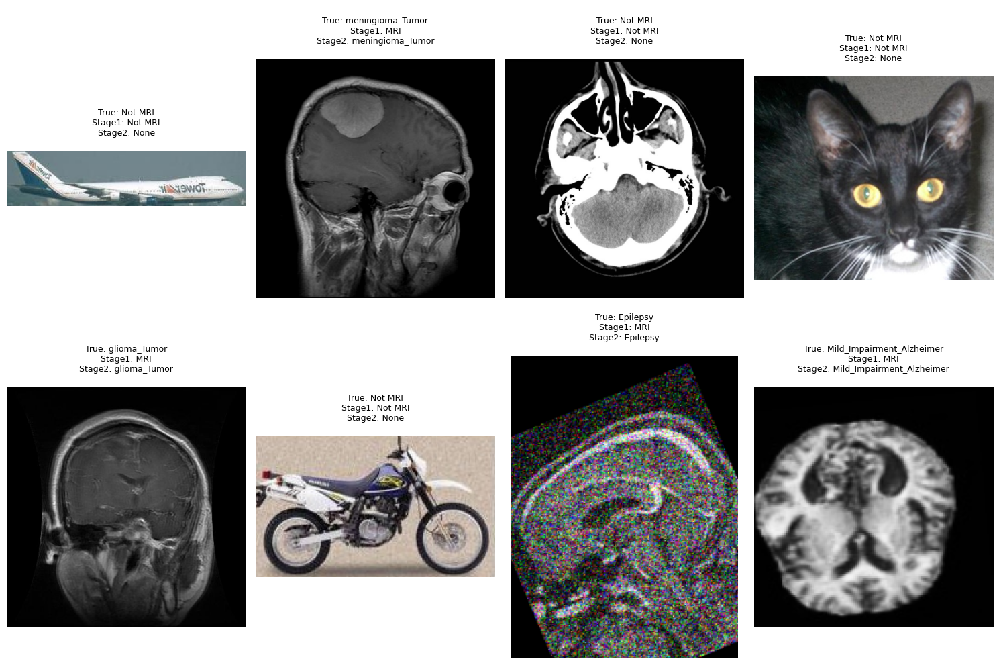

In [84]:
import matplotlib.pyplot as plt
import random

# =========================
# Dataset Paths
# =========================
base_path = "/kaggle/input/datasets/tonymalak999/brain-dataset2/Dataset(2)"

mri_path = os.path.join(base_path, "MRI")
not_mri_path = os.path.join(base_path, "Not_MRI")

# =========================
# Collect Random Images
# =========================
def get_random_images(num_images=6):
    image_paths = []
    true_labels = []

    # MRI images
    for class_name in os.listdir(mri_path):
        class_folder = os.path.join(mri_path, class_name)
        images = os.listdir(class_folder)
        if images:
            img = random.choice(images)
            image_paths.append(os.path.join(class_folder, img))
            true_labels.append(class_name)

    # Not MRI images
    for class_name in os.listdir(not_mri_path):
        class_folder = os.path.join(not_mri_path, class_name)
        images = os.listdir(class_folder)
        if images:
            img = random.choice(images)
            image_paths.append(os.path.join(class_folder, img))
            true_labels.append("Not MRI")

    combined = list(zip(image_paths, true_labels))
    random.shuffle(combined)

    return combined[:num_images]


# =========================
# Test and Display
# =========================
samples = get_random_images(8)

plt.figure(figsize=(15, 10))

for i, (img_path, true_label) in enumerate(samples):

    result = full_pipeline_prediction(img_path)

    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 4, i+1)
    plt.imshow(img)
    plt.axis("off")

    title = f"""
True: {true_label}
Stage1: {result['Stage1_Label']}
Stage2: {result['Stage2_Label']}
"""
    plt.title(title, fontsize=9)

plt.tight_layout()
plt.show()

Total test images found: 36


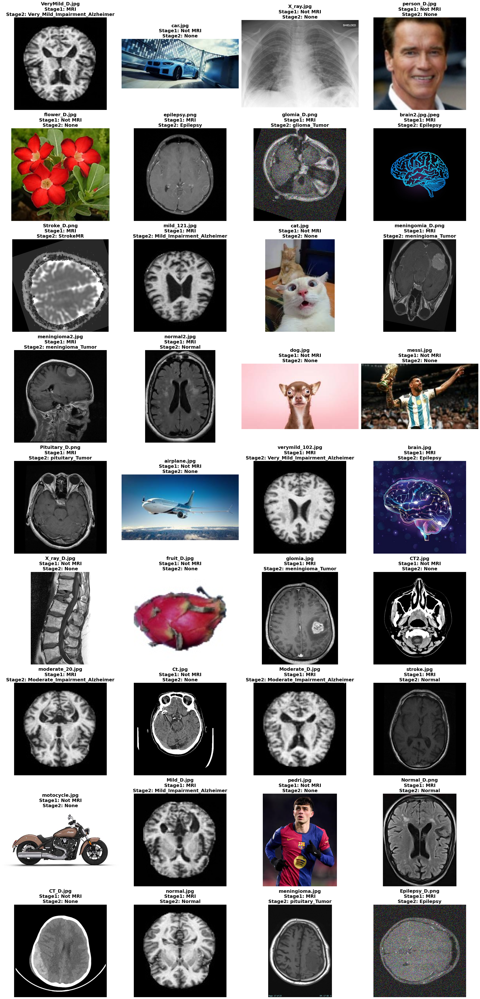

In [85]:
import os
import cv2
import math
import matplotlib.pyplot as plt

# =========================
# Path
# =========================
test_path = "/kaggle/input/datasets/tonymalak999/brain-dataset-final-test"

# =========================
# Collect All Images
# =========================
exts = (".png", ".jpg", ".jpeg", ".PNG", ".JPG", ".JPEG")
all_images = []

for root, dirs, files in os.walk(test_path):
    for file in files:
        if file.endswith(exts):
            all_images.append(os.path.join(root, file))

print("Total test images found:", len(all_images))

# =========================
# Predict + Display All
# =========================
cols = 4
rows = math.ceil(len(all_images) / cols)

plt.figure(figsize=(26, rows * 6))  # كبرنا الشكل عشان يستوعب النص

for i, img_path in enumerate(all_images):

    # Prediction
    result = full_pipeline_prediction(img_path)

    # Read image
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # استخراج اسم الصورة من اللينك
    image_name = os.path.basename(img_path)

    plt.subplot(rows, cols, i+1)
    plt.imshow(img)
    plt.axis("off")

    plt.title(
        f"{image_name}\nStage1: {result['Stage1_Label']}\nStage2: {result['Stage2_Label']}",
        fontsize=18,          # خط كبير
        fontweight="bold",
        color="black"
    )

plt.tight_layout()
plt.show()